
OPTIMAL TRAFFIC SIGNAL TIMINGS
--------------------------------
Road 1: 69.58 seconds
Road 2: 24.12 seconds
Road 3: 15.00 seconds
Road 4: 51.29 seconds
--------------------------------
Total Cycle Time: 160.0 seconds
Minimum Waiting Time: 16968.42 vehicle-seconds per cycle


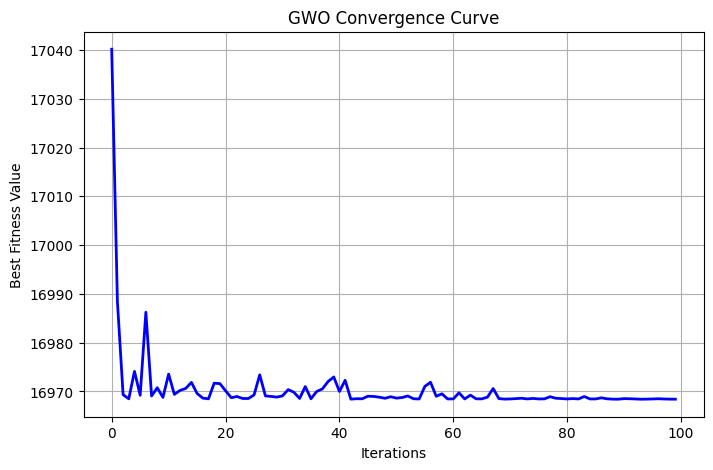

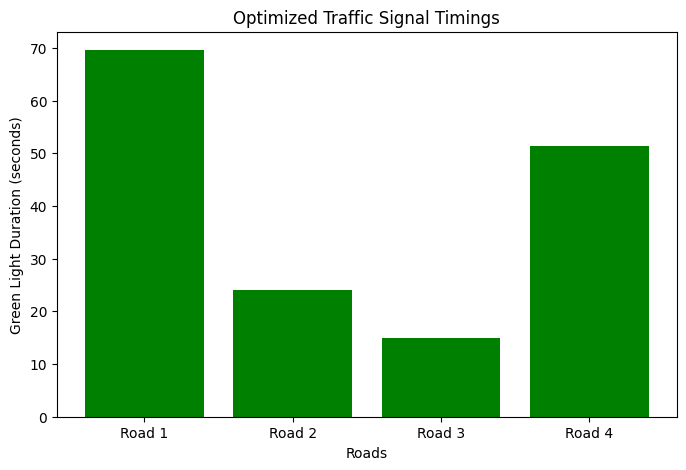

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# --------------------------------
# 1. Problem Parameters
# --------------------------------

num_wolves = 20
num_roads = 4
max_iterations = 100

cycle_time = 160       # Total signal cycle time (seconds)
min_green = 15         # Minimum green time
max_green = 70         # Maximum green time

# Vehicle arrival rates (vehicles per minute)
arrival_rates = np.array([18, 12, 10, 15])

# Saturation flow (vehicles per second)
saturation_flow = 0.5

# --------------------------------
# 2. Boundary Handling
# --------------------------------

def repair(position):
    """
    Ensure green timings satisfy:
    - Minimum and maximum green time
    - Total cycle time = 160 seconds
    """
    low = -1000
    high = 1000

    for _ in range(60):
        mid = (low + high) / 2
        adjusted = np.clip(
            position - mid,
            min_green,
            max_green
        )

        if np.sum(adjusted) > cycle_time:
            low = mid
        else:
            high = mid

    return np.clip(
        position - (low + high) / 2,
        min_green,
        max_green
    )


# --------------------------------
# 3. Fitness Function
# --------------------------------

def fitness(position):

    total_delay = 0

    for i in range(num_roads):

        green = position[i]
        red = cycle_time - green

        # Vehicle arrival rate per second
        arrival_rate = arrival_rates[i] / 60

        # Vehicles arriving during one cycle
        vehicles_arrived = arrival_rate * cycle_time

        # Vehicles served during green signal
        vehicles_served = saturation_flow * green

        # Remaining queue
        remaining_queue = max(
            0,
            vehicles_arrived - vehicles_served
        )

        # Approximate waiting time
        delay = (
            arrival_rate * red**2 / 2
            + remaining_queue * cycle_time
        )

        total_delay += delay

    return total_delay


# --------------------------------
# 4. Initialize Wolf Population
# --------------------------------

wolves = np.random.uniform(
    min_green,
    max_green,
    (num_wolves, num_roads)
)

for i in range(num_wolves):
    wolves[i] = repair(wolves[i])


# Store convergence values
convergence_curve = []

# --------------------------------
# 5. Grey Wolf Optimization
# --------------------------------

for iteration in range(max_iterations):

    # Evaluate fitness
    fitness_values = np.array([
        fitness(wolf) for wolf in wolves
    ])

    # Sort wolves based on fitness
    sorted_indices = np.argsort(fitness_values)

    alpha = wolves[sorted_indices[0]].copy()
    beta = wolves[sorted_indices[1]].copy()
    delta = wolves[sorted_indices[2]].copy()

    alpha_fitness = fitness_values[sorted_indices[0]]

    convergence_curve.append(alpha_fitness)

    # Parameter decreases from 2 to 0
    a = 2 - 2 * iteration / max_iterations

    # Update positions
    for i in range(num_wolves):

        X = wolves[i].copy()

        r1 = np.random.random(num_roads)
        r2 = np.random.random(num_roads)

        A1 = 2 * a * r1 - a
        C1 = 2 * r2

        D_alpha = abs(C1 * alpha - X)
        X1 = alpha - A1 * D_alpha

        r1 = np.random.random(num_roads)
        r2 = np.random.random(num_roads)

        A2 = 2 * a * r1 - a
        C2 = 2 * r2

        D_beta = abs(C2 * beta - X)
        X2 = beta - A2 * D_beta

        r1 = np.random.random(num_roads)
        r2 = np.random.random(num_roads)

        A3 = 2 * a * r1 - a
        C3 = 2 * r2

        D_delta = abs(C3 * delta - X)
        X3 = delta - A3 * D_delta

        # Final position update
        new_position = (X1 + X2 + X3) / 3

        # Apply constraints
        wolves[i] = repair(new_position)


# --------------------------------
# 6. Find Optimal Solution
# --------------------------------

fitness_values = np.array([
    fitness(wolf) for wolf in wolves
])

best_index = np.argmin(fitness_values)

best_solution = wolves[best_index]
best_fitness = fitness_values[best_index]

# --------------------------------
# 7. Display Results
# --------------------------------

print("\nOPTIMAL TRAFFIC SIGNAL TIMINGS")
print("--------------------------------")

for i in range(num_roads):
    print(
        f"Road {i+1}: "
        f"{best_solution[i]:.2f} seconds"
    )

print("--------------------------------")
print("Total Cycle Time:",
      round(np.sum(best_solution), 2), "seconds")

print("Minimum Waiting Time:",
      round(best_fitness, 2),
      "vehicle-seconds per cycle")


# --------------------------------
# 8. Plot Convergence Curve
# --------------------------------

plt.figure(figsize=(8, 5))

plt.plot(
    convergence_curve,
    color='blue',
    linewidth=2
)

plt.title("GWO Convergence Curve")
plt.xlabel("Iterations")
plt.ylabel("Best Fitness Value")

plt.grid(True)
plt.show()


# --------------------------------
# 9. Plot Optimal Signal Timings
# --------------------------------

plt.figure(figsize=(8, 5))

plt.bar(
    ["Road 1", "Road 2", "Road 3", "Road 4"],
    best_solution,
    color="green"
)

plt.title("Optimized Traffic Signal Timings")
plt.xlabel("Roads")
plt.ylabel("Green Light Duration (seconds)")

plt.show()